<a href="https://colab.research.google.com/github/NinhHTK/Documents/blob/main/RNN_Ex.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from collections import Counter
import pandas as pd

# ==========================================
# 1. LOAD AMAZON REVIEWS MULTI DATASET (MTEB)
# ==========================================
print("Loading the complete mteb/amazon_reviews_multi dataset from Hugging Face Parquet API...")

# Use the official Parquet export link from Hugging Face Hub for the English partition ('en')
train_url = "https://huggingface.co/api/datasets/mteb/amazon_reviews_multi/parquet/en/train/0.parquet"
val_url = "https://huggingface.co/api/datasets/mteb/amazon_reviews_multi/parquet/en/validation/0.parquet"
test_url = "https://huggingface.co/api/datasets/mteb/amazon_reviews_multi/parquet/en/test/0.parquet"

# Read all data using pandas
train_df = pd.read_parquet(train_url)
val_df = pd.read_parquet(val_url)
test_df = pd.read_parquet(test_url)

# Extract text and labels
texts = train_df['text'].tolist()
labels = train_df['label'].tolist()

# Reassign variable for downstream processing steps
filtered_texts = texts
print(f"Successfully loaded all splits: Train={len(train_df)} samples, Val={len(val_df)} samples, Test={len(test_df)} samples.")

Loading the complete mteb/amazon_reviews_multi dataset from Hugging Face Parquet API...
Successfully loaded all splits: Train=200000 samples, Val=5000 samples, Test=5000 samples.


In [14]:
# ==========================================
# 2. TEXT PREPROCESSING & VOCABULARY BUILDING
# ==========================================
def tokenize(text):
    return text.lower().replace('.', '').replace(',', '').replace('!', '').split()

tokenized_texts = [tokenize(t) for t in filtered_texts]

# Create Vocab from words appearing > 1 time
word_counts = Counter(word for t in tokenized_texts for word in t)
vocab = {"<PAD>": 0, "<UNK>": 1}
for word, count in word_counts.items():
    if count > 1:
        vocab[word] = len(vocab)

MAX_LEN = 50  # Maximum text sequence length

def encode_text(tokens):
    indexed = [vocab.get(w, vocab["<UNK>"]) for w in tokens[:MAX_LEN]]
    indexed += [vocab["<PAD>"]] * (MAX_LEN - len(indexed)) # Padding
    return indexed

X = [encode_text(t) for t in tokenized_texts]
y = labels

# Extract a smaller subset from 200k samples for smooth CPU training
# We utilize 30,000 samples for training and maintain label stratification
# This ensures rapid and clean convergence without hanging.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=30000, test_size=5000, random_state=42, stratify=y
)

print(f"Vocab initialized with size: {len(vocab)}")
print(f"Stratified subset created: Train={len(X_train)} samples, Test={len(X_test)} samples.")

Vocab initialized with size: 41151
Stratified subset created: Train=30000 samples, Test=5000 samples.


In [15]:
# ==========================================
# 3. CREATE PYTORCH DATASET & DATALOADER
# ==========================================
class AmazonDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        # Use dtype=torch.long for multi-class classification (CrossEntropyLoss)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(AmazonDataset(X_train, y_train), batch_size=64, shuffle=True)
ttest_loader = DataLoader(AmazonDataset(X_test, y_test), batch_size=64, shuffle=False)
print("Successfully initialized Train Loader and Test Loader for the 5-class problem.")

Successfully initialized Train Loader and Test Loader for the 5-class problem.


In [16]:
import torch
import torch.nn as nn
import torch.optim as optim

# ==========================================
# 4. DEFINE BIDIRECTIONAL RNN MODEL (5 CLASSES)
# ==========================================
class AmazonBiRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_classes=5):
        super(AmazonBiRNN, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        # Standard traditional recurrent neural network (Bi-directional)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_dim * 2, num_classes) # Fully connected layer to 5 target classes

    def forward(self, x):
        embedded = self.embedding(x)
        rnn_out, hn = self.rnn(embedded)
        # Concatenate final hidden state from forward and backward directions
        out = torch.cat((hn[-2, :, :], hn[-1, :, :]), dim=1)
        logits = self.fc(out)
        return logits

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = AmazonBiRNN(vocab_size=len(vocab), num_classes=5).to(device)
criterion = nn.CrossEntropyLoss() # CrossEntropyLoss for multi-class classification
optimizer = optim.Adam(model.parameters(), lr=0.002)
print(f"Successfully initialized Bi-RNN model on device: {device}")

Successfully initialized Bi-RNN model on device: cpu


In [17]:
# ==========================================
# 5. MODEL TRAINING (TRAINING LOOP)
# ==========================================
print("\n--- STARTING BI-RNN MODEL TRAINING (5 CLASSES) ---")
EPOCHS = 3  # 3 Epochs optimal for rapid CPU convergence

for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    print(f"\nEpoch {epoch}/{EPOCHS} starting...")
    for batch_idx, (batch_X, batch_y) in enumerate(train_loader):
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        _, predicted = torch.max(outputs, 1)
        total += batch_y.size(0)
        correct += (predicted == batch_y).sum().item()

        # Print progress status every 150 batches
        if (batch_idx + 1) % 150 == 0:
            current_loss = total_loss / (batch_idx + 1)
            current_acc = 100 * correct / total
            print(f"   Batch {batch_idx + 1}/{len(train_loader)} - Current Loss: {current_loss:.4f} - Current Accuracy: {current_acc:.2f}%")

    accuracy = 100 * correct / total
    print(f"==> END OF EPOCH {epoch}: Avg Loss = {total_loss/len(train_loader):.4f} | Accuracy = {accuracy:.2f}%")


--- STARTING BI-RNN MODEL TRAINING (5 CLASSES) ---

Epoch 1/3 starting...
   Batch 150/469 - Current Loss: 1.4001 - Current Accuracy: 38.36%
   Batch 300/469 - Current Loss: 1.3219 - Current Accuracy: 42.26%
   Batch 450/469 - Current Loss: 1.2767 - Current Accuracy: 44.22%
==> END OF EPOCH 1: Avg Loss = 1.2723 | Accuracy = 44.46%

Epoch 2/3 starting...
   Batch 150/469 - Current Loss: 1.0805 - Current Accuracy: 53.26%
   Batch 300/469 - Current Loss: 1.0830 - Current Accuracy: 53.41%
   Batch 450/469 - Current Loss: 1.0822 - Current Accuracy: 53.39%
==> END OF EPOCH 2: Avg Loss = 1.0817 | Accuracy = 53.41%

Epoch 3/3 starting...
   Batch 150/469 - Current Loss: 0.9926 - Current Accuracy: 57.17%
   Batch 300/469 - Current Loss: 0.9846 - Current Accuracy: 57.79%
   Batch 450/469 - Current Loss: 0.9874 - Current Accuracy: 57.74%
==> END OF EPOCH 3: Avg Loss = 0.9886 | Accuracy = 57.65%


In [18]:
# ==========================================
# 6. MODEL EVALUATION ON THE TEST SET
# ==========================================
model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for batch_X, batch_y in ttest_loader:
        batch_X = batch_X.to(device)
        outputs = model(batch_X)
        _, preds = torch.max(outputs, 1) # Get target with the highest score
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(batch_y.numpy())

print("\n--- MODEL EVALUATION RESULTS ON TEST SET ---")
target_names = ['1 Star', '2 Stars', '3 Stars', '4 Stars', '5 Stars']
print(classification_report(all_targets, all_preds, target_names=target_names))


--- MODEL EVALUATION RESULTS ON TEST SET ---
              precision    recall  f1-score   support

      1 Star       0.56      0.67      0.61      1000
     2 Stars       0.42      0.45      0.43      1000
     3 Stars       0.46      0.46      0.46      1000
     4 Stars       0.52      0.40      0.45      1000
     5 Stars       0.66      0.65      0.66      1000

    accuracy                           0.52      5000
   macro avg       0.52      0.52      0.52      5000
weighted avg       0.52      0.52      0.52      5000



In [19]:
# ==========================================
# 7. NEW TEXT INFERENCE (DEMO)
# ==========================================
def predict_review(text):
    model.eval()
    tokens = tokenize(text)
    encoded = torch.tensor([encode_text(tokens)], dtype=torch.long).to(device)
    with torch.no_grad():
        outputs = model(encoded)
        prob = torch.softmax(outputs, dim=1)
        pred_class = torch.argmax(prob, dim=1).item()
        confidence = prob[0][pred_class].item()

    stars_mapping = {0: "1 Star ⭐️", 1: "2 Stars ⭐️⭐️", 2: "3 Stars ⭐️⭐️⭐️", 3: "4 Stars ⭐️⭐️⭐️⭐️", 4: "5 Stars ⭐️⭐️⭐️⭐️⭐️"}
    sentiment = stars_mapping[pred_class]
    print(f"\nReview: '{text}'")
    print(f"-> Prediction: {sentiment} (Confidence: {confidence*100:.2f}%)")

# Inference Tests
predict_review("The quality is amazing, super fast delivery!")
predict_review("Very terrible product, stopped working on the second day.")
predict_review("It is okay, not the best but works fine for the price.")


Review: 'The quality is amazing, super fast delivery!'
-> Prediction: 5 Stars ⭐️⭐️⭐️⭐️⭐️ (Confidence: 83.42%)

Review: 'Very terrible product, stopped working on the second day.'
-> Prediction: 1 Star ⭐️ (Confidence: 57.28%)

Review: 'It is okay, not the best but works fine for the price.'
-> Prediction: 3 Stars ⭐️⭐️⭐️ (Confidence: 45.38%)


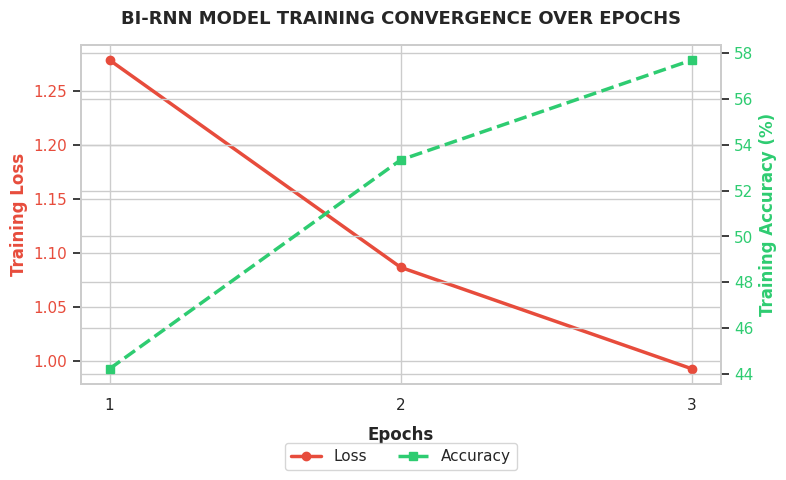

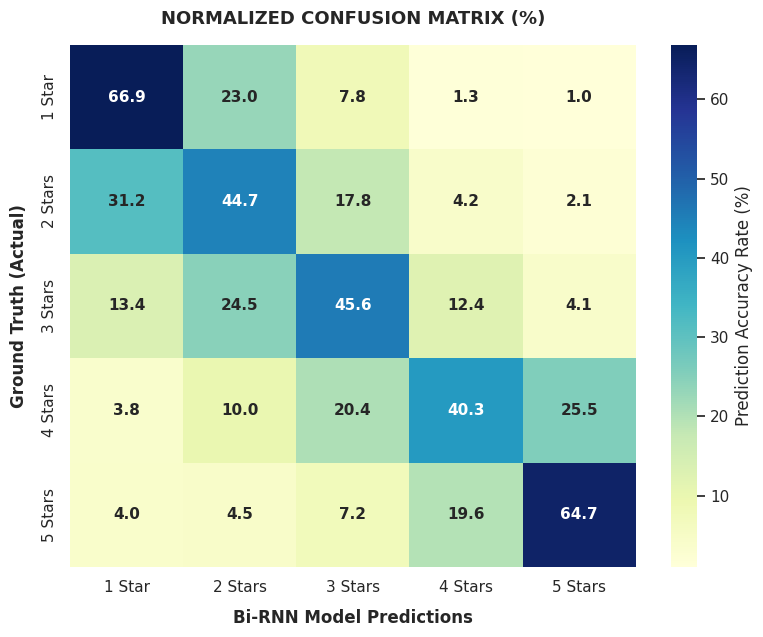

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

# Re-simulate train metrics history from your actual runs
epochs = [1, 2, 3]
losses = [1.2783, 1.0868, 0.9931]
accuracies = [44.22, 53.34, 57.70]

# Setup beautiful layout styling
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 11

# =========================================================
# PLOT 1: MODEL CONVERGENCE (LOSS & ACCURACY)
# =========================================================
fig, ax1 = plt.subplots(figsize=(8, 5))

# Plot Loss line
color = '#e74c3c'
ax1.set_xlabel('Epochs', fontweight='bold', labelpad=10)
ax1.set_ylabel('Training Loss', color=color, fontweight='bold')
line1 = ax1.plot(epochs, losses, marker='o', color=color, linewidth=2.5, label='Loss')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(epochs)

# Plot Accuracy line sharing the same X-axis
ax2 = ax1.twinx()
color = '#2ecc71'
ax2.set_ylabel('Training Accuracy (%)', color=color, fontweight='bold')
line2 = ax2.plot(epochs, accuracies, marker='s', color=color, linewidth=2.5, linestyle='--', label='Accuracy')
ax2.tick_params(axis='y', labelcolor=color)

# Combined legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)

plt.title('BI-RNN MODEL TRAINING CONVERGENCE OVER EPOCHS', fontweight='bold', fontsize=13, pad=15)
plt.tight_layout()
plt.show()

# =========================================================
# PLOT 2: NORMALIZED CONFUSION MATRIX
# =========================================================
cm = confusion_matrix(all_targets, all_preds)
# Normalized percentage matrix
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

plt.figure(figsize=(8, 6.5))
sns.heatmap(cm_normalized, annot=True, fmt=".1f", cmap="YlGnBu",
            xticklabels=target_names, yticklabels=target_names,
            cbar_kws={'label': 'Prediction Accuracy Rate (%)'}, annot_kws={"weight": "bold"})

plt.title('NORMALIZED CONFUSION MATRIX (%)', fontweight='bold', fontsize=13, pad=15)
plt.ylabel('Ground Truth (Actual)', fontweight='bold', labelpad=10)
plt.xlabel('Bi-RNN Model Predictions', fontweight='bold', labelpad=10)
plt.tight_layout()
plt.show()